In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
figsave='figures_draft'

### GSEA heatmap

In [3]:
import gseapy as gp

In [4]:
import pickle
with open("/lustre/scratch126/cellgen/lotfollahi/so21/patientAtlases/Gabitto2024NatureMed/SuppTable6.pkl", "rb") as f:
    genesets = pickle.load(f)

In [5]:
import pickle
with open("../DEGs/pyDESeq2/iA_DEGs_sig.pkl", "rb") as f:
    iA_DEGs_sig = pickle.load(f)

with open("../DEGs/pyDESeq2/DESeq2_iNeurons_results_v3_sig.pkl", "rb") as f:
    iN_DEGs_sig = pickle.load(f)


In [6]:
iA_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iAstrocytes_results_sig_nDEGs.csv"), index_col=0)
iN_nDEGs_df= pd.read_csv(os.path.join("../DEGs/pyDESeq2/", "DESeq2_iNeurons_results_v3_sig_nDEGs.csv"), index_col=0)

iA_top_genes = iA_nDEGs_df[iA_nDEGs_df['nDEGs']>=5].index
iN_top_genes = iN_nDEGs_df[iN_nDEGs_df['nDEGs']>=5].index

In [7]:
import requests
def get_enrichr_library(library_name):
    url = "https://maayanlab.cloud/Enrichr/geneSetLibrary"
    r = requests.get(
        url,
        params={"mode": "text", "libraryName": library_name},
        timeout=60,
    )
    r.raise_for_status()
    genesets = {}
    for line in r.text.strip().splitlines():
        parts = line.split("\t")
        genesets[parts[0]] = [g.split(",")[0] for g in parts[2:]]
    return genesets

#tabula = get_enrichr_library("Tabula_Sapiens")
GO = get_enrichr_library("GO_Biological_Process_2025")
reactome = get_enrichr_library("Reactome_Pathways_2024")
hallmarks = get_enrichr_library("MSigDB_Hallmark_2020")
kegg = get_enrichr_library("KEGG_2021_Human")
go_mf = get_enrichr_library("GO_Molecular_Function_2025")
go_cc = get_enrichr_library("GO_Cellular_Component_2025")
wiki = get_enrichr_library("WikiPathways_2024_Human")
archs4_tissues = get_enrichr_library("ARCHS4_Tissues")
gtex_tissues = get_enrichr_library("GTEx_Tissues_V8_2023")
human_gene_atlas = get_enrichr_library("Human_Gene_Atlas")
cellmarker = get_enrichr_library("CellMarker_2024")
panglao = get_enrichr_library("PanglaoDB_Augmented_2021")
azimuth = get_enrichr_library("Azimuth_2023")
descartes = get_enrichr_library("Descartes_Cell_Types_and_Tissue_2021")
compartments = get_enrichr_library("COMPARTMENTS_Curated_2025")
tissues_curated = get_enrichr_library("TISSUES_Curated_2025")

In [8]:
import gseapy as gp

def enrichment_heatmap(gene_dict, gene_sets=None, organism='human', top_n=5, fdr_cutoff=0.05):
    """
    Perform enrichment analysis and create a heatmap of top GO terms.

    Parameters:
        gene_dict (dict): Dictionary containing list of genes to perform GEA on
        gene_sets (list): List of gene sets for enrichment analysis (default GO + MSigDB).
        organism (str): Organism for enrichment ('human', 'mouse', etc.).
        top_n (int): Number of GO terms to keep.
        fdr_cutoff (float): FDR threshold for significance.

    Returns:
        GO_res (DataFrame): Filtered -log10(p-value) enrichment matrix.
        enr_dict (dict): Dictionary of raw enrichment results per perturbation.
    """
    
    if gene_sets is None:
        gene_sets = ['GO_Biological_Process_2025','MSigDB_Hallmark_2020','GO_Cellular_Component_2025','GO_Molecular_Function_2025',
                     'Reactome_2022','CellMarker_2024' #'Reactome_Pathways_2024',
                    ]

    # Run enrichment for each GP
    enr_dict = {}
    for key in gene_dict:
        enr = gp.enrichr(
            gene_list=gene_dict[key]['variable'].to_list(),
            gene_sets=gene_sets,
            organism=organism,
            outdir=None
        )
        if isinstance(enr.results, pd.DataFrame) and not enr.results.empty:
            enr_dict[key] = enr.results.sort_values("Adjusted P-value")
        else:
            print(f"No enrichment results for {key}")
            enr_dict[key] = pd.DataFrame(columns=["Term", "Adjusted P-value"])

    # Transform results to -log10(p-value)
    pvalues = {}
    for key, df in enr_dict.items():
        df_top = df[["Term","Adjusted P-value"]].head(top_n).copy()
        df_top = df_top.rename(columns={'Adjusted P-value': key}).set_index("Term")
        df_top[key] = -np.log10(df_top[key])
        pvalues[key] = df_top

    minuslogp = pd.concat(pvalues.values(), axis=0, join="outer")
    minuslogp = minuslogp.groupby(level=0).sum()

    # keep significant GO terms
    minuslogp_bool = (minuslogp <= -np.log10(fdr_cutoff)).all(axis=1)
    GO_res = minuslogp[~minuslogp_bool]

    print(f"GO terms shape (significant): {GO_res.shape}")
    
    return GO_res, enr_dict

In [9]:
GO_res_a, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iA_DEGs_sig.items() if k in iA_top_genes},
    gene_sets=[genesets],#go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.05,
)

2026-10-08 12:37:00,395 [ERROR] No hits returned for all input gene sets!


No enrichment results for EIF4A3
GO terms shape (significant): (21, 30)


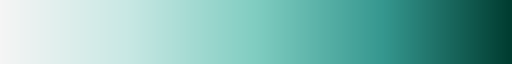

In [10]:
from matplotlib.colors import LinearSegmentedColormap

palette = [
    #"#533211",
    #"#8c5322",
    #"#dfc17c",
    #"#f5e7c3",
    "#f5f5f5",
    "#c8e8e4",
    "#80cdc1",
    "#35978f",
    #"#03675e",
    "#003c30"
]

cmap = LinearSegmentedColormap.from_list("white_teal", palette)
cmap

In [11]:
import seaborn as sns

In [12]:
sns.set_style('ticks')

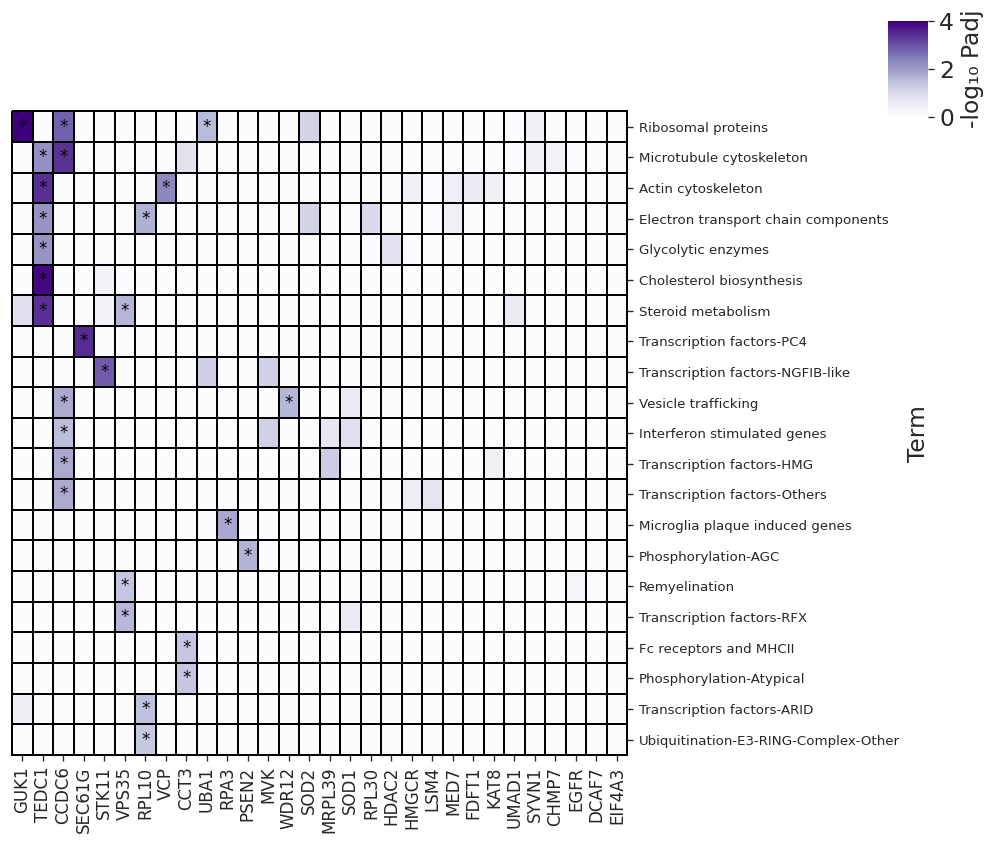

In [13]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_a.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_a.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap='Purples',
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.8, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(11,8),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_Gabitto_iAstrocytes_v3_2.pdf', dpi=300)

In [14]:
GO_res_n, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iN_DEGs_sig.items() if k in iN_top_genes},
    gene_sets=[genesets],#go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.05,
)

2026-10-08 12:37:03,073 [ERROR] No hits returned for all input gene sets!
2026-10-08 12:37:03,140 [ERROR] No hits returned for all input gene sets!


No enrichment results for CCT3
No enrichment results for DNMT1
GO terms shape (significant): (14, 24)


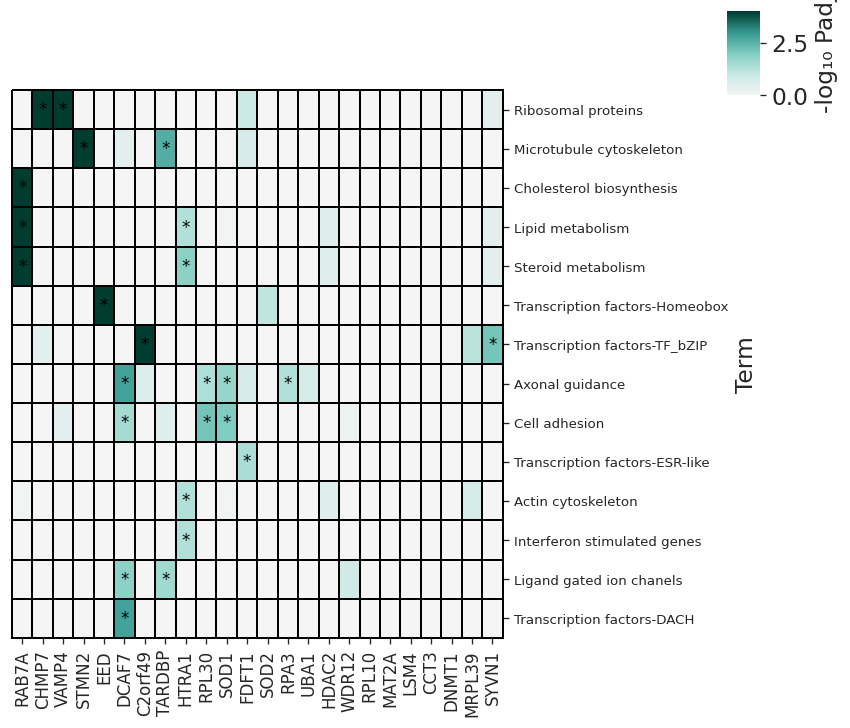

In [15]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_n.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_n.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap=cmap,
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.8, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(9,7),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_Gabitto_iNeurons_v3.pdf', dpi=300)

### NMF modules

In [16]:
programs = pd.read_excel('/lustre/scratch126/cellgen/lotfollahi/so21/patientAtlases/Meir2025Biorxiv/media-3.xlsx', sheet_name='DEGs')
print (programs.shape)
programs.head(5)

ExN = [i for i in programs.program.unique() if i.startswith('EXC L2-3')]
ExN = programs[programs.program.isin(ExN)]
ExN = ExN.groupby('program')['gene'].apply(list).to_dict()

Ast = [i for i in programs.program.unique() if i.startswith('AST')]
Ast = programs[programs.program.isin(Ast)]
Ast = Ast.groupby('program')['gene'].apply(list).to_dict()

genesets = Ast

(36836, 9)


In [17]:
GO_res_a, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iA_DEGs_sig.items() if k in iA_top_genes},
    gene_sets=[genesets],#go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.05,
)

2026-10-07 20:23:13,350 [ERROR] No hits returned for all input gene sets!


No enrichment results for UMAD1
GO terms shape (significant): (7, 30)


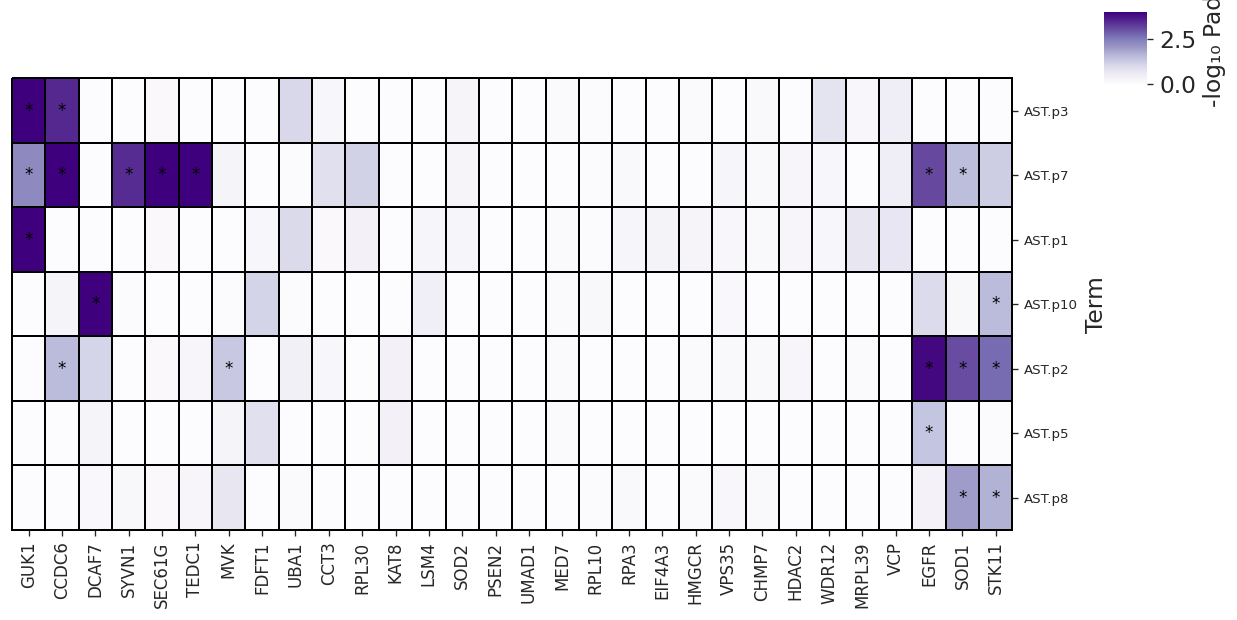

In [18]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_a.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_a.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap='Purples',
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.95, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(12,6),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_NMF_iAstrocytes_v3_2.pdf', dpi=300)

In [19]:
genesets = ExN

GO_res_N, enr_dict = enrichment_heatmap(
    gene_dict={k:v for k,v in iN_DEGs_sig.items() if k in iN_top_genes},
    gene_sets=[genesets],#go_mf, go_cc, wiki,],
    top_n=6,
    fdr_cutoff=0.05,
)

2026-10-07 20:23:14,074 [ERROR] No hits returned for all input gene sets!
2026-10-07 20:23:14,133 [ERROR] No hits returned for all input gene sets!


No enrichment results for CCT3
No enrichment results for RPA3
GO terms shape (significant): (9, 24)


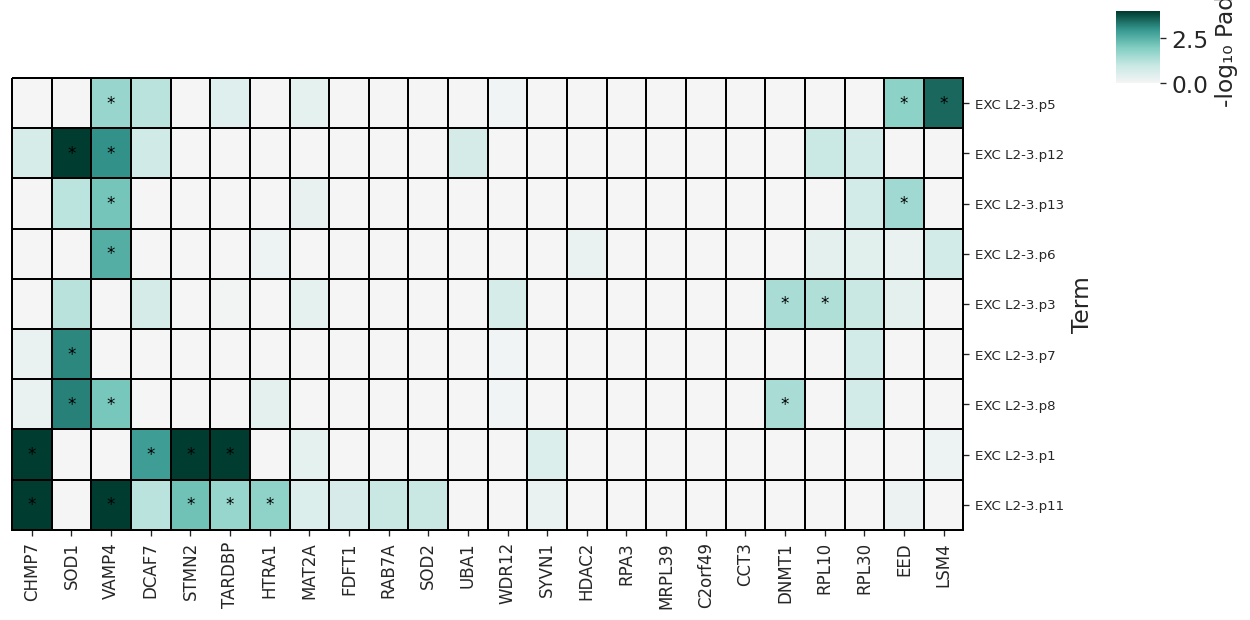

In [20]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_N.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_N.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap=cmap,
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.95, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(12,6),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_NMF_iNeurons_v3.pdf', dpi=300)

### DEGs

In [21]:
# Load Gabbito gene signatures
import pickle
import pandas as pd

with open(
    "/lustre/scratch126/cellgen/lotfollahi/so21/patientAtlases/Gabitto2024NatureMed/SuppTable6.pkl",
    "rb"
) as f:
    genesets = pickle.load(f)

# Load MSigDB Hallmark gene signatures used in Fig. 3
hallmarks = pd.read_csv(
    "/nfs/team361/so21/genesets/h.all.v2026.1.Hs.symbols.gmt.txt",
    sep="\t",
    header=None
)

hallmark_dict = (
    hallmarks
    .set_index(0)
    .iloc[:, 1:]
    .apply(lambda row: row.dropna().tolist(), axis=1)
    .to_dict()
)

# Combine Gabbito and Hallmark signatures
genesets_fig3 = genesets | hallmark_dict

print(f"Gabbito signatures: {len(genesets)}")
print(f"Hallmark signatures: {len(hallmark_dict)}")
print(f"Total signatures: {len(genesets_fig3)}")

# iAstrocyte enrichment
GO_res_a, enr_dict_a = enrichment_heatmap(
    gene_dict={k: v for k, v in iA_DEGs_sig.items() if k in iA_top_genes},
    gene_sets=[genesets_fig3],
    top_n=6,
    fdr_cutoff=0.05,
)

# iNeuron enrichment
GO_res_n, enr_dict_n = enrichment_heatmap(
    gene_dict={k: v for k, v in iN_DEGs_sig.items() if k in iN_top_genes},
    gene_sets=[genesets_fig3],
    top_n=6,
    fdr_cutoff=0.05,
)

Gabbito signatures: 129
Hallmark signatures: 50
Total signatures: 179


2026-10-07 20:49:43,181 [ERROR] No hits returned for all input gene sets!


GO terms shape (significant): (34, 30)
No enrichment results for CCT3
GO terms shape (significant): (26, 24)


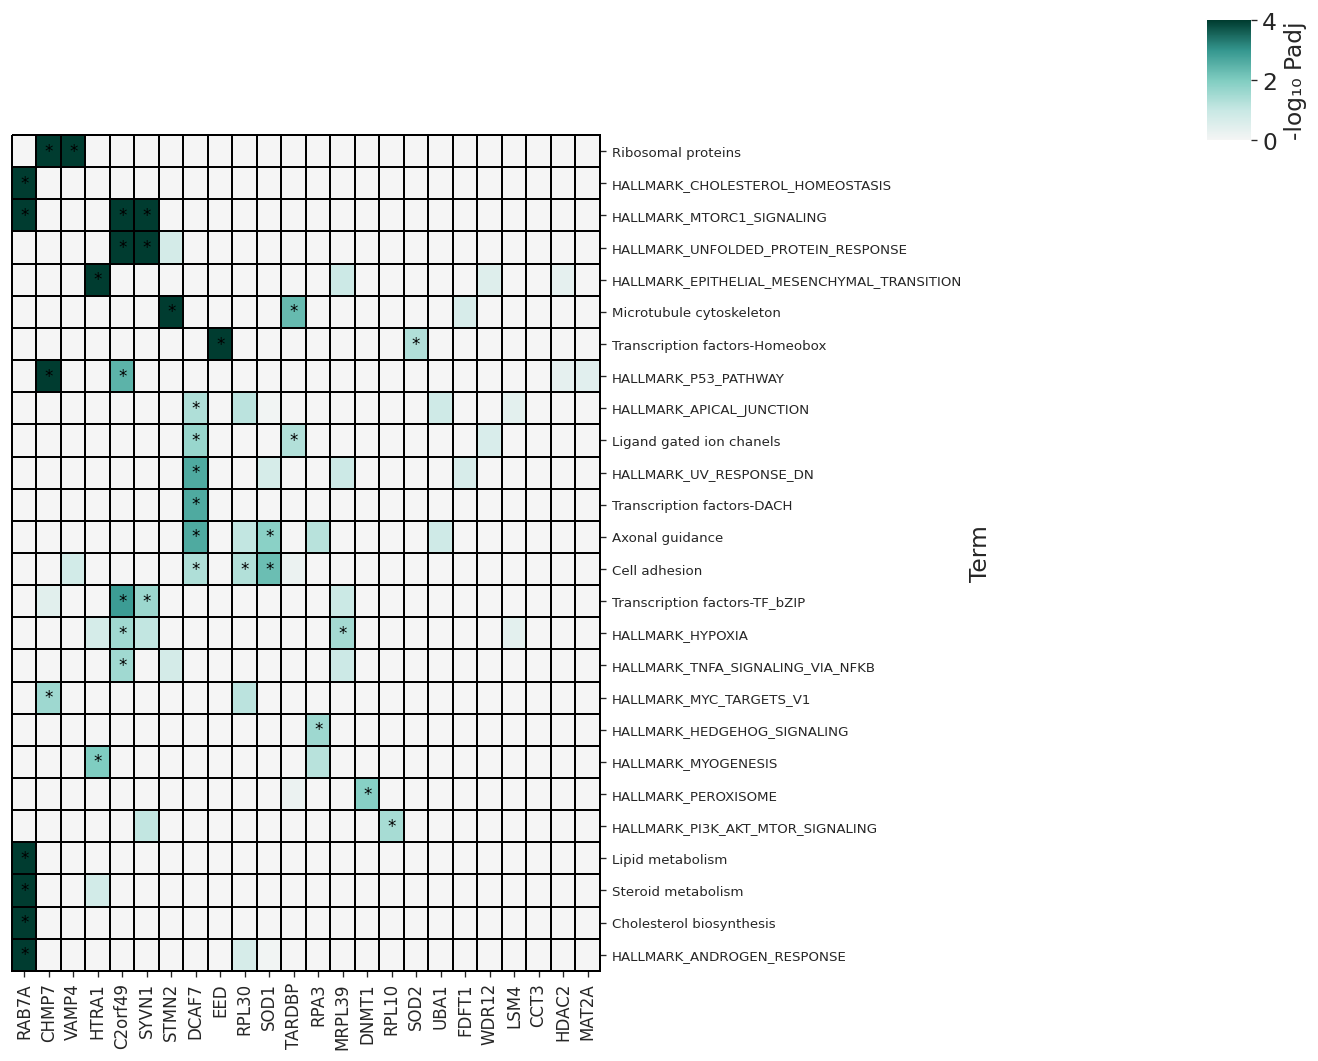

In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_n.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_n.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap=cmap,
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.95, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(12,10),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_hallmarksGabitto_iNeurons.pdf', dpi=300)

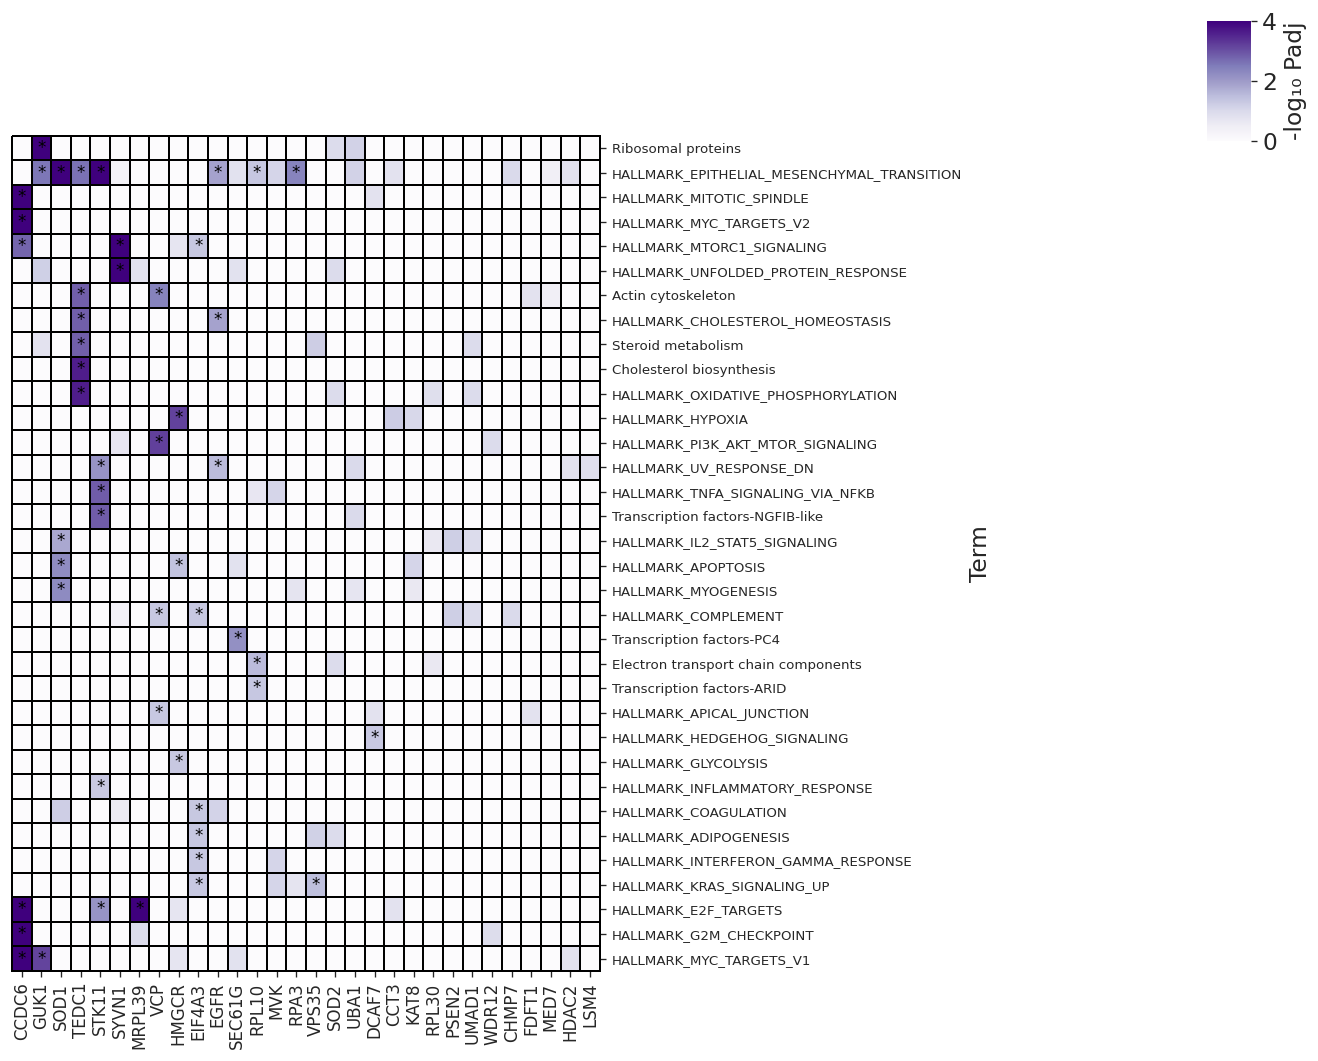

In [27]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Significance threshold for p < 0.05
sig_threshold = -np.log10(0.05)  # ≈ 1.301
annot = GO_res_a.applymap(lambda x: '*' if x > sig_threshold else '')

# Plot with annotations
g = sns.clustermap(
    GO_res_a.astype(float),
    annot=annot, fmt='',  # Show * directly
    annot_kws={'color': 'black', 'fontsize': 10},
    vmax=4, cmap='Purples',
    linewidths=1, linecolor='black', clip_on=False,yticklabels=1,
    #dendrogram_ratio=(0,0),
    cbar_pos=(0.95, 0.8, 0.03, 0.1),
    cbar_kws={'label': u'-log\u2081\u2080 Padj'},
    figsize=(12,10),
)

# Adjust label sizes
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.ax_heatmap.tick_params(axis='y', labelsize=8)
g.ax_heatmap.tick_params(axis='x', labelsize=10)

plt.savefig('figures_draft/figS3_heatmap_hallmarksGabitto_iAstrocytes.pdf', dpi=300)